# Voyager 1: la distancia también depende de quién escucha
**Categoría: EDA (análisis exploratorio de datos). Corte: 22 de octubre de 2026 a las 00:00 UTC.**

Me pregunto cómo cambia la demora de las comunicaciones entre destinos y si alejarse del Sol implica alejarse de la Tierra cada día. Comparo seis destinos y reviso la trayectoria histórica de Voyager 1. Analizo efemérides calculadas por JPL, no mediciones de mensajes reales. No entreno un modelo ni genero previsiones propias.

## Ruta de lectura y glosario
Primero documento las fuentes y preparo los datos; después comparo destinos, reviso la historia y compruebo el efecto del movimiento terrestre.
- **Efeméride:** una tabla de posiciones y velocidades calculadas por una institución astronómica para fechas concretas.
- **Demora de ida:** distancia dividida por la velocidad de la luz, 299.792,458 km/s.
- **Ida y vuelta aproximada:** el doble de esa demora. Congelo la geometría para hacer comparable la escala; no calculo el itinerario exacto de dos señales con emisores en movimiento.
- **Centro terrestre / solar:** comparo distancias medidas desde el centro de la Tierra o del Sol. No son la misma distancia.
- **UTC:** uso la misma hora mundial para todas las filas; las 00:00 UTC del corte son las 02:00 en la España peninsular.

## 1. Origen y unidad de observación
Descargo las respuestas de la [API de JPL Horizons](https://ssd-api.jpl.nasa.gov/doc/horizons.html). Conservo sus parámetros, cabeceras y tablas en `fuentes/`, y las direcciones y huellas digitales en `fuentes.json`. Cada fila representa un destino en un instante, no una transmisión observada.

Solicito vectores geométricos (`VEC_CORR=NONE`), unidades km y segundos, fechas UT, centro terrestre `500@399` y tabla 3. Leo `RG` como distancia, `LT` como demora geométrica y `RR` como velocidad radial. La historia está muestreada cada 30 días desde el 6 de septiembre de 1977, no exactamente una vez por mes. Para 2026 uso pasos diarios y una segunda consulta desde el Sol (`500@10`).

Comparo Luna, Marte y Júpiter como destinos, no como sondas; New Horizons y las Voyager sí son sondas. No atribuyo la distancia al centro de un planeta a un vehículo concreto. La selección es ilustrativa, no un censo de misiones.

In [1]:
# importo las herramientas y mantengo todas las rutas relativas a esta carpeta
from pathlib import Path
import json
import hashlib
import platform
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
base = Path.cwd()
color_principal = '#446ddf'
corte = pd.Timestamp('2026-10-22')
velocidad_luz = 299792.458
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python', platform.python_version(), '| pandas', pd.__version__)

Python 3.12.14 | pandas 3.0.1


## 2. Preparación
Conservo los CSV de extracción y preparo copias. Convierto las fechas con un formato explícito en inglés y excluyo cualquier fila posterior al corte: Horizons devuelve también el extremo final solicitado del 23 de octubre. No relleno huecos. Compruebo que la demora publicada coincide con la distancia dividida por la velocidad de la luz.

In [2]:
# preparo las tablas y excluyo el extremo posterior a mi fecha de corte
tablas = {}
for nombre in ['comparacion', 'historia', 'diario_2026', 'diario_sol_2026']:
    tabla = pd.read_csv(base / f'{nombre}.csv')
    tabla['fecha'] = pd.to_datetime(tabla['fecha_utc'], format='%Y-%b-%d %H:%M:%S.%f')
    tabla = tabla.loc[tabla['fecha'].le(corte)].copy()
    tabla['horas_ida'] = tabla['segundos_ida'] / 3600
    tabla['horas_ida_vuelta_aprox'] = tabla['horas_ida'] * 2
    tablas[nombre] = tabla
comparacion = tablas['comparacion']
historia = tablas['historia']
diario = tablas['diario_2026']
solar = tablas['diario_sol_2026']
for nombre, tabla in tablas.items():
    assert tabla['fecha'].max() <= corte
    assert tabla['distancia_km'].gt(0).all()
    assert ((tabla['distancia_km'] / velocidad_luz - tabla['segundos_ida']).abs() < 0.00001).all()
    assert not tabla.duplicated(subset=['destino','fecha'] if 'destino' in tabla else ['fecha']).any()
    print(nombre, len(tabla), 'filas válidas')
assert len(comparacion) == 6
assert len(diario) == 295 and diario['fecha'].diff().dropna().eq(pd.Timedelta(days=1)).all()
for fuente in json.loads((base / 'fuentes.json').read_text(encoding='utf-8')):
    assert hashlib.sha256((base / fuente['archivo']).read_bytes()).hexdigest() == fuente['sha256']
print('Compruebo unidades, fechas, duplicados, continuidad y huellas de las fuentes.')

comparacion 6 filas válidas
historia 599 filas válidas
diario_2026 295 filas válidas
diario_sol_2026 295 filas válidas
Compruebo unidades, fechas, duplicados, continuidad y huellas de las fuentes.


## 3. Análisis: la misma señal, esperas muy distintas
Divido la distancia por la velocidad de la luz. La señal de radio viaja a esa velocidad en el vacío: no comparo la velocidad de los vehículos. Duplico el resultado solo como aproximación de ida y vuelta sin tiempos de procesamiento, turnos de antena ni incidencias. En la tabla dejo todos los valores; en el gráfico uso escala logarítmica porque la Luna y Voyager no caben de forma útil en una escala lineal. Cada salto de diez en el eje significa multiplicar por diez la espera.

,destino,distancia_km,segundos_ida,horas_ida,horas_ida_vuelta_aprox
0,Luna,3.895188e+05,1.2993,0.0004,0.0007
1,Marte,2.261787e+08,754.4509,0.2096,0.4191
2,Júpiter,8.447535e+08,2817.7943,0.7827,1.5654
3,New Horizons,9.881214e+09,32960.1834,9.1556,18.3112
4,Voyager 2,2.159793e+10,72042.9414,20.0119,40.0239
5,Voyager 1,2.582997e+10,86159.4978,23.9332,47.8664


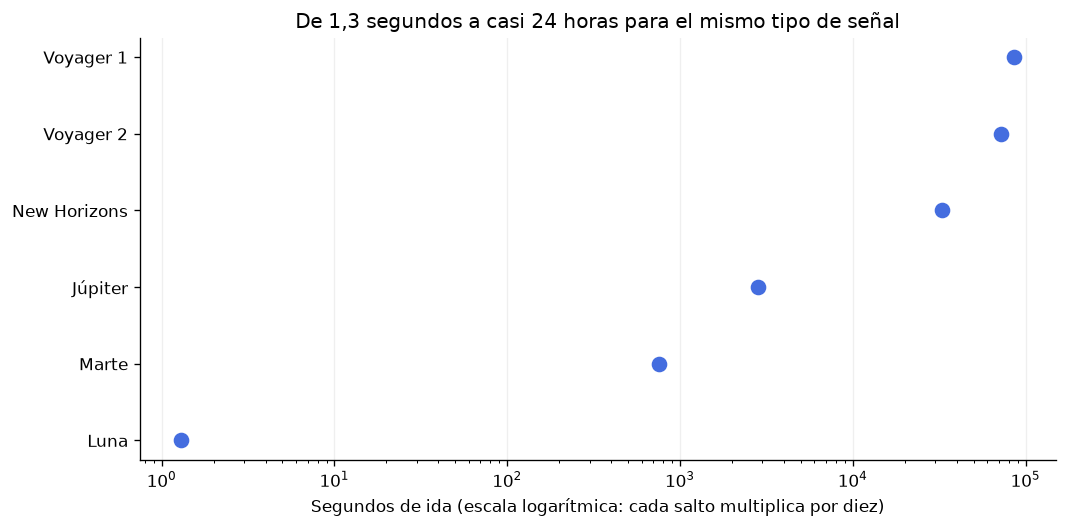

Voyager 1: 23.933194 horas de ida; 47.866388 de ida y vuelta aproximada.


In [3]:
# comparo todos los destinos en el mismo instante y hago explícita la aproximación
display(comparacion[['destino', 'distancia_km', 'segundos_ida', 'horas_ida', 'horas_ida_vuelta_aprox']].round(4))
fig, eje = plt.subplots(figsize=(9, 4.5))
eje.scatter(comparacion['segundos_ida'], comparacion['destino'], color=color_principal, s=70)
eje.set_xscale('log')
eje.set_xlabel('Segundos de ida (escala logarítmica: cada salto multiplica por diez)')
eje.set_title('De 1,3 segundos a casi 24 horas para el mismo tipo de señal')
eje.grid(axis='x', alpha=.2)
fig.tight_layout()
plt.show()
v_actual = comparacion.loc[comparacion['destino'].eq('Voyager 1')].iloc[0]
print(f"Voyager 1: {v_actual.horas_ida:.6f} horas de ida; {v_actual.horas_ida_vuelta_aprox:.6f} de ida y vuelta aproximada.")

Encuentro unos 1,3 segundos hasta la Luna y casi 24 horas hasta Voyager 1. En el mismo corte, Marte está a unos 12,6 minutos, Júpiter a 47 minutos, New Horizons a 9,2 horas y Voyager 2 a 20 horas. Interpreto estas cifras como una fotografía de las distancias: no como tiempos permanentes de cada destino ni como disponibilidad real de comunicación.

## 4. Casi medio siglo para ganar un día de distancia
Recorro la serie histórica de Voyager 1 desde el día posterior al lanzamiento. El eje vertical expresa horas de ida desde la Tierra. Mantengo el muestreo de 30 días: no intento identificar giros diarios con esa resolución. No extrapolo hacia noviembre; la fecha futura del hito pertenece a NASA.

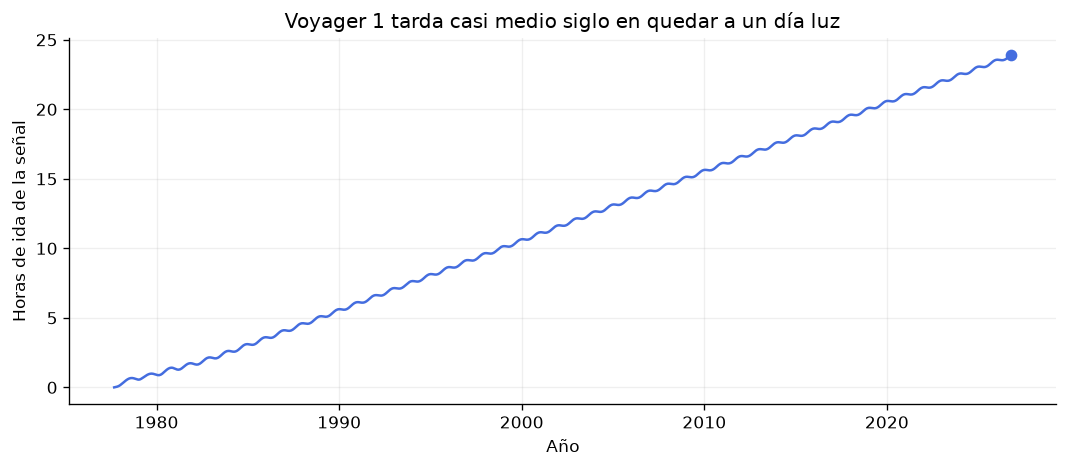

,fecha,horas_ida
0,1977-09-06,0.000357
598,2026-10-19,23.924717


In [4]:
# recorro la historia sin añadir puntos futuros calculados por mí
fig, eje = plt.subplots(figsize=(9, 4))
eje.plot(historia['fecha'], historia['horas_ida'], color=color_principal)
eje.scatter([corte], [v_actual.horas_ida], color=color_principal)
eje.set(title='Voyager 1 tarda casi medio siglo en quedar a un día luz', ylabel='Horas de ida de la señal', xlabel='Año')
eje.grid(alpha=.2)
fig.tight_layout()
plt.show()
display(historia.iloc[[0,-1]][['fecha','horas_ida']])

## 5. Compruebo la sorpresa: alejarse del Sol y acercarse a la Tierra
Comparo la distancia terrestre con la solar día a día. Resto a cada serie su valor del 1 de enero para ver el cambio, no para confundir sus distancias absolutas. Busco intervalos entre dos medianoches consecutivas en los que disminuye la demora terrestre. No cuento esos intervalos como días completos con velocidad negativa en todos sus instantes.

Intervalos de 24 horas con menor distancia terrestre: 93
Extremos muestreados: 2026-01-21 2026-04-24
Reducción de ida, segundos: 135.7155016810575


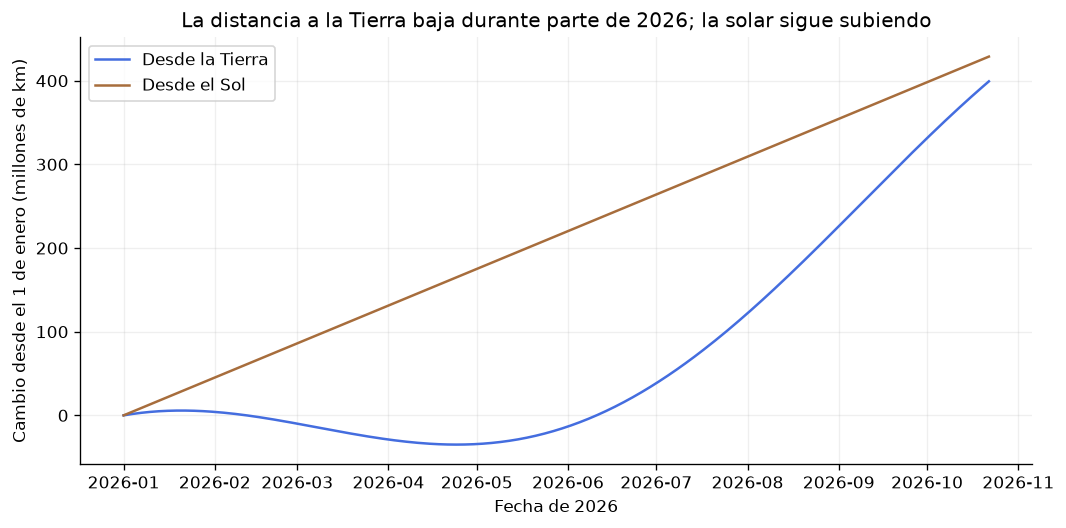

In [5]:
# compruebo los intervalos diarios y confronto las dos referencias
diario['cambio_segundos'] = diario['segundos_ida'].diff()
acercamientos = diario.loc[diario['cambio_segundos'].lt(0)]
maximo_previo = diario.loc[diario['fecha'].lt('2026-03-01')].sort_values('segundos_ida').iloc[-1]
minimo_posterior = diario.loc[diario['fecha'].between('2026-03-01','2026-06-01')].sort_values('segundos_ida').iloc[0]
reduccion = float(maximo_previo.segundos_ida - minimo_posterior.segundos_ida)
assert len(acercamientos) == 93
assert solar['distancia_km'].diff().dropna().gt(0).all()
print('Intervalos de 24 horas con menor distancia terrestre:', len(acercamientos))
print('Extremos muestreados:', str(maximo_previo.fecha.date()), str(minimo_posterior.fecha.date()))
print('Reducción de ida, segundos:', reduccion)
fig, eje = plt.subplots(figsize=(9,4.5))
for tabla, etiqueta, color in [(diario,'Desde la Tierra',color_principal),(solar,'Desde el Sol','#a76d3c')]:
    eje.plot(tabla['fecha'], (tabla['distancia_km'] - tabla['distancia_km'].iloc[0]) / 1000000, label=etiqueta, color=color)
eje.set(title='La distancia a la Tierra baja durante parte de 2026; la solar sigue subiendo', ylabel='Cambio desde el 1 de enero (millones de km)', xlabel='Fecha de 2026')
eje.legend()
eje.grid(alpha=.2)
fig.tight_layout()
plt.show()

Encuentro 93 intervalos diarios consecutivos de acercamiento terrestre: del 21 de enero al 24 de abril entre los extremos de la tabla. La demora de ida disminuye unos 135,7 segundos, dos minutos y cuarto. Entretanto, la distancia solar sube en todos los intervalos diarios consultados. No interpreto esta diferencia como una vuelta de Voyager: la Tierra también se mueve y modifica la separación.

## 6. Robustez y límites
Compruebo la sorpresa con muestreos más espaciados, para evitar que dependa de una diferencia diminuta entre dos filas. No identifico el instante exacto de máximo o mínimo con pasos de un día. Los valores geométricos no incluyen la corrección por el movimiento durante el vuelo de la señal; redondeo en el artículo. No calculo una hora exacta de respuesta, ni una fecha propia del día luz. Conservo como previsión de NASA el 18 de noviembre de 2026, publicado en su página del hito.

In [6]:
# reviso si el descenso permanece al espaciar las observaciones y guardo resultados
for paso in [2, 7, 14]:
    muestra = diario.iloc[::paso]
    intervalos = int(muestra['distancia_km'].diff().lt(0).sum())
    assert intervalos > 0
    print(f'Con pasos de {paso} días también encuentro descensos: {intervalos} intervalos.')
resultados = {'categoria':'EDA','corte_utc':'2026-10-22T00:00:00Z','voyager_1_horas_ida':float(v_actual.horas_ida),'voyager_1_horas_ida_vuelta_aprox':float(v_actual.horas_ida_vuelta_aprox),'intervalos_diarios_acercamiento':len(acercamientos),'reduccion_ida_segundos':reduccion,'inicio_descenso':str(maximo_previo.fecha.date()),'fin_descenso':str(minimo_posterior.fecha.date()),'filas_historia':len(historia),'filas_diarias':len(diario)}
(base / 'resultados.json').write_text(json.dumps(resultados,ensure_ascii=False,indent=2),encoding='utf-8')
comparacion.to_csv(base / 'comparacion_limpia.csv',index=False)
datos_web = {'comparacion':comparacion[['destino','segundos_ida']].to_dict(orient='records'),'historia':[{'fecha':str(r.fecha.date()),'horas':r.horas_ida} for r in historia.itertuples()], 'diario':[{'fecha':str(a.fecha.date()),'tierra':(a.distancia_km-diario.iloc[0].distancia_km)/1e6,'sol':(b.distancia_km-solar.iloc[0].distancia_km)/1e6} for a,b in zip(diario.itertuples(),solar.itertuples())]}
(base / 'datos_web.json').write_text(json.dumps(datos_web,ensure_ascii=False),encoding='utf-8')
display(pd.Series(resultados))

Con pasos de 2 días también encuentro descensos: 47 intervalos.
Con pasos de 7 días también encuentro descensos: 13 intervalos.
Con pasos de 14 días también encuentro descensos: 7 intervalos.


categoria                                            EDA
corte_utc                           2026-10-22T00:00:00Z
voyager_1_horas_ida                            23.933194
voyager_1_horas_ida_vuelta_aprox               47.866388
intervalos_diarios_acercamiento                       93
reduccion_ida_segundos                        135.715502
inicio_descenso                               2026-01-21
fin_descenso                                  2026-04-24
filas_historia                                       599
filas_diarias                                        295
dtype: object

## 7. Conclusión
Compruebo que la distancia convierte el control espacial en una conversación pausada: en el corte analizado, la ida y vuelta geométrica aproximada de Voyager 1 ya ronda 47 horas y 52 minutos. También encuentro una matización importante: una nave que se aleja del Sol no tiene por qué alejarse de la Tierra todos los días. Aporto esa comparación de referencias y su magnitud; no presento como descubrimiento propio el movimiento orbital ni el hito anunciado por NASA.

## Fuentes y reproducción
- [JPL Horizons: documentación de la API](https://ssd-api.jpl.nasa.gov/doc/horizons.html).
- [JPL Horizons: manual y definiciones de vectores](https://ssd.jpl.nasa.gov/horizons/manual.html).
- [NASA: Voyager 1 y el día luz](https://science.nasa.gov/mission/voyager/voyager-1/voyager-1-what-is-a-light-day/).
- [NASA: preguntas frecuentes sobre Voyager](https://science.nasa.gov/mission/voyager/frequently-asked-questions/).

Abro este notebook en la misma carpeta que sus CSV y `fuentes.json`, instalo `requirements.txt` y ejecuto todas las celdas en orden. No necesito conexión para repetir el análisis. Para renovar las fuentes ejecuto `descargar.py` en Windows; ese paso requiere conexión y conserva la descarga anterior si ya existe. Las respuestas originales incluyen el 23 de octubre para cerrar el intervalo; mi preparación lo excluye. No publico los paquetes instalados ni rutas personales.